<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/2_quantum/topics_in_qm/aqm_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Topics in Quantum Mechanics* — `aqm_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# AQM Chapter 1 — Figures (v3 — final physics consistency fixes)
**Applications of Quantum Mechanics · Particles in Magnetic Fields**

Generates Figures 1.1 – 1.8 used in `aqm_ch01.qmd`.
All physical and visibility issues from the review have been addressed.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Arc, Circle, FancyArrow
from matplotlib.path import Path
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D
import os

# ── Common style ──────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#1e1e2e',
    'axes.facecolor':   '#1e1e2e',
    'text.color':       '#cdd6f4',
    'axes.labelcolor':  '#cdd6f4',
    'xtick.color':      '#cdd6f4',
    'ytick.color':      '#cdd6f4',
    'axes.edgecolor':   '#45475a',
    'grid.color':       '#313244',
    'font.family':      'DejaVu Sans',
    'font.size':        12,
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
    'mathtext.fontset': 'cm',      # Computer Modern for math
})

BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'

os.makedirs('figures/ch01', exist_ok=True)
SAVE = lambda name: plt.savefig(f'figures/ch01/{name}', dpi=150,
                                 bbox_inches='tight', facecolor='#1e1e2e')
print('Setup complete.')


Setup complete.


## Figure 1.1 — Landau Level Energy Ladder

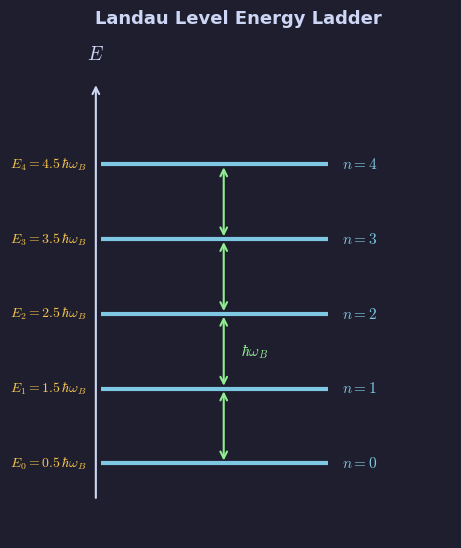

Fig 1.1 saved.


In [2]:
# FIX 1.1:
# - Raw string used throughout for consistent LaTeX rendering
# - Level lines extended wider, thicker for better visibility on dark slides
# - Spacing arrows fan out (separate x positions per gap)
# - E-axis drawn as actual arrow spine

fig, ax = plt.subplots(figsize=(5.5, 6.5))
ax.set_xlim(0, 4.5)
ax.set_ylim(-0.5, 6.2)
ax.axis('off')

n_levels = 5
x_left, x_right = 0.8, 3.2

for n in range(n_levels):
    E = n + 0.5
    # Level lines — wider, higher lw
    ax.hlines(E, x_left, x_right, colors=BLUE, linewidths=3.0, zorder=3)
    # n label (right side)
    ax.text(x_right + 0.15, E, fr'$n={n}$',
            va='center', color=BLUE, fontsize=11)
    # Energy label (left side) — all raw string fr'' for consistent rendering
    ax.text(x_left - 0.15, E, fr'$E_{n}={n+0.5:.1f}\,\hbar\omega_B$',
            va='center', ha='right', color=YELLOW, fontsize=10)

# Spacing double-arrow between consecutive levels
arr_x = 2.1
for n in range(n_levels - 1):
    ax.annotate('', xy=(arr_x, n + 1.5), xytext=(arr_x, n + 0.5),
                arrowprops=dict(arrowstyle='<->', color=GREEN, lw=1.5))
# Single label near the middle arrow
ax.text(arr_x + 0.18, 2.0, r'$\hbar\omega_B$', color=GREEN, fontsize=11, va='center')

# E-axis as annotated arrow
ax.annotate('', xy=(0.75, 5.6), xytext=(0.75, 0.0),
            arrowprops=dict(arrowstyle='->', color='#cdd6f4', lw=1.5))
ax.text(0.75, 5.85, r'$E$', color='#cdd6f4', fontsize=14,
        ha='center', va='bottom', style='italic')

ax.set_title('Landau Level Energy Ladder', color='#cdd6f4', pad=10)

SAVE('fig01_landau_ladder.png')
plt.show()
print('Fig 1.1 saved.')


## Figure 1.2 — Landau Fan (Degeneracy vs Flux)

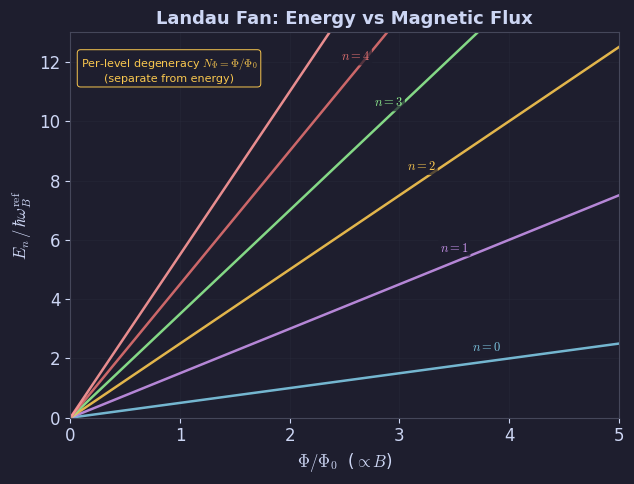

Fig 1.2 saved.


In [3]:
# FIG 1.2 — Landau Fan
# Physics: E_n = (n+½)ℏω_B, ω_B ∝ B ∝ Φ/Φ₀
# Hence E_n/(ℏω_B^ref) = (n+½)·(Φ/Φ₀)  [ω_B^ref ≡ eΦ₀/(mA), A = sample area]
# Slope of each line = (n+½): higher Landau index rises faster with B
# Note: this plot shows energy. Degeneracy N ∝ Φ/Φ₀ is a separate physical quantity.

fig, ax = plt.subplots(figsize=(6.5, 5))

Phi = np.linspace(0.01, 5, 300)
colors_n = [BLUE, PURPLE, YELLOW, GREEN, RED, '#ff9a9a']
label_x  = [3.8, 3.5, 3.2, 2.9, 2.6]   # staggered x positions to prevent overlap

for n in range(6):
    E = (n + 0.5) * Phi          # E_n = (n+½)·(Φ/Φ₀) in units of ℏω_B^ref
    ax.plot(Phi, E, color=colors_n[n], lw=1.8, alpha=0.9)
    if n < 5:
        lx = label_x[n]
        ly = (n + 0.5) * lx
        label = '$n=' + str(n) + '$'
        ax.text(lx, ly + 0.25, label,
                color=colors_n[n], fontsize=9,
                ha='center', va='bottom',
                bbox=dict(boxstyle='round,pad=0.15',
                          fc='#1e1e2e', ec='none', alpha=0.7))

ax.set_xlabel(r'$\Phi / \Phi_0$  ($\propto B$)', fontsize=12)
ax.set_ylabel(r'$E_n\,/\,\hbar\omega_B^{\mathrm{ref}}$', fontsize=12)
ax.set_title('Landau Fan: Energy vs Magnetic Flux', color='#cdd6f4')
ax.set_xlim(0, 5)
ax.set_ylim(0, 13)
ax.grid(True, alpha=0.25)

# Degeneracy note — separate text box to distinguish from energy lines
ax.text(0.9, 12.2,
        r'Per-level degeneracy $N_\Phi = \Phi/\Phi_0$' '\n'
        r'(separate from energy)',
        color=YELLOW, fontsize=8, ha='center', va='top',
        bbox=dict(boxstyle='round,pad=0.3', fc='#1e1e2e', ec=YELLOW, lw=0.7))

plt.tight_layout()
SAVE('fig02_landau_fan.png')
plt.show()
print('Fig 1.2 saved.')


## Figure 1.3 — LLL Wavefunctions in Symmetric Gauge

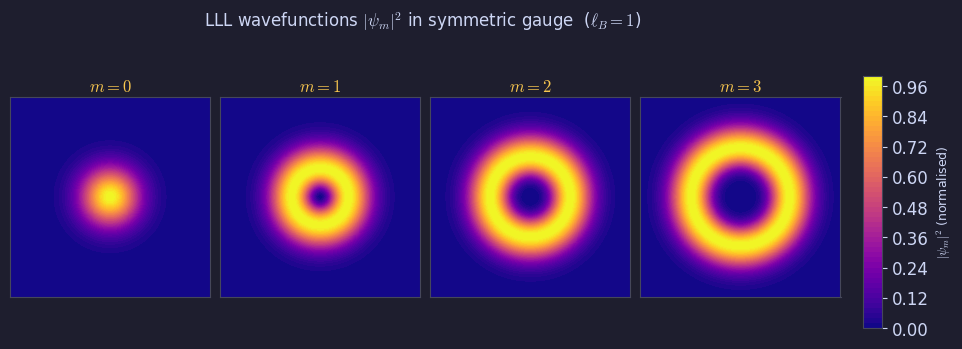

Fig 1.3 saved.


In [4]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3.5))

ell = 1.0
xy  = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(xy, xy)
r2   = X**2 + Y**2

ims = []
for ax, m in zip(axes, [0, 1, 2, 3]):
    psi  = (np.sqrt(r2)**m) * np.exp(-r2 / (4 * ell**2))
    prob = psi**2
    prob /= prob.max()

    im = ax.contourf(X, Y, prob, levels=50,
                     cmap='plasma', vmin=0, vmax=1)
    ims.append(im)
    ax.set_aspect('equal')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.set_title('$m = ' + str(m) + '$', color=YELLOW, fontsize=12, pad=4)
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor('#45475a')

# Place colorbar in a dedicated axes in the right margin
fig.subplots_adjust(right=0.88, wspace=0.05)
cax  = fig.add_axes([0.90, 0.12, 0.018, 0.72])   # [left, bottom, width, height]
cbar = fig.colorbar(ims[-1], cax=cax)
cbar.set_label(r'$|\psi_m|^2$ (normalised)', color='#cdd6f4', fontsize=9)
cbar.ax.yaxis.set_tick_params(color='#cdd6f4')
plt.setp(cbar.ax.yaxis.get_ticklabels(), color='#cdd6f4')

fig.suptitle(r'LLL wavefunctions $|\psi_m|^2$ in symmetric gauge  ($\ell_B = 1$)',
             color='#cdd6f4', fontsize=12, y=1.03)

SAVE('fig03_LLL_wavefunctions.png')
plt.show()
print('Fig 1.3 saved.')

## Figure 1.4 — Aharonov–Bohm Setup

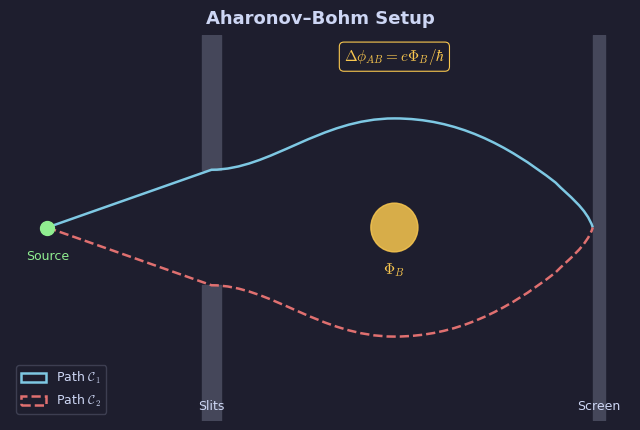

Fig 1.4 saved.


In [5]:
# FIG 1.4 — Aharonov–Bohm Setup
# Bezier bug fix: MOVETO + LINETO(straight) + CURVE4*9(curve, 3 segments)
# CURVE4 requires points in multiples of 3 → 9 points = exactly 3 cubic segments

from matplotlib.path import Path as MPath
import matplotlib.patches as mpatch
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlim(0, 10)
ax.set_ylim(-0.5, 5.5)
ax.axis('off')

# Source
ax.plot(0.6, 2.5, 'o', color=GREEN, ms=10, zorder=5)
ax.text(0.6, 2.0, 'Source', color=GREEN, ha='center', fontsize=9)

# Double slit barrier
for yb, yt in [(-1, 1.6), (3.4, 5.5)]:
    ax.fill_between([3.1, 3.4], [yb, yb], [yt, yt], color='#45475a')
ax.text(3.25, -0.35, 'Slits', color='#cdd6f4', ha='center', fontsize=9)

# Solenoid (placed between slits and screen)
sol_x, sol_y, sol_r = 6.2, 2.5, 0.38
sol = Circle((sol_x, sol_y), sol_r, color=YELLOW, zorder=5, alpha=0.85)
ax.add_patch(sol)
ax.text(sol_x, sol_y, r'$\otimes$', color='#1e1e2e',
        ha='center', va='center', fontsize=12, fontweight='bold')
ax.text(sol_x, sol_y - sol_r - 0.35, r'$\Phi_B$', color=YELLOW,
        ha='center', fontsize=11)

def bezier_path(ax, verts, codes, color, ls='-', lw=1.8, label=None):
    path  = MPath(verts, codes)
    patch = mpatch.PathPatch(path, facecolor='none',
                              edgecolor=color, lw=lw, ls=ls,
                              label=label, zorder=3)
    ax.add_patch(patch)

# Upper path: MOVETO(source) → LINETO(slit entrance) → CURVE4*9 (3 cubic segments)
# Each CURVE4 segment = 2 control points + endpoint (3 pts each)
verts1 = [
    (0.6,  2.5),               # MOVETO: source
    (3.25, 3.4),               # LINETO: slit upper exit
    (4.2,  3.4), (5.0, 4.2), (6.2, 4.2),   # CURVE4 seg1: arc up and over solenoid
    (7.2,  4.2), (8.0, 3.8), (8.8, 3.2),   # CURVE4 seg2: descend
    (9.0,  3.0), (9.3, 2.8), (9.4, 2.5),   # CURVE4 seg3: arrive at screen
]
codes1 = [MPath.MOVETO, MPath.LINETO] + [MPath.CURVE4]*9
bezier_path(ax, verts1, codes1, BLUE, ls='-',  label=r'Path $\mathcal{C}_1$')

# Lower path: same structure, arc below solenoid
verts2 = [
    (0.6,  2.5),               # MOVETO
    (3.25, 1.6),               # LINETO: slit lower exit
    (4.2,  1.6), (5.0, 0.8), (6.2, 0.8),   # CURVE4 seg1
    (7.2,  0.8), (8.0, 1.2), (8.8, 1.8),   # CURVE4 seg2
    (9.0,  2.0), (9.3, 2.2), (9.4, 2.5),   # CURVE4 seg3
]
codes2 = [MPath.MOVETO, MPath.LINETO] + [MPath.CURVE4]*9
bezier_path(ax, verts2, codes2, RED, ls='--', label=r'Path $\mathcal{C}_2$')

# Screen
ax.fill_between([9.4, 9.6], [-0.5, -0.5], [5.5, 5.5], color='#45475a')
ax.text(9.5, -0.35, 'Screen', color='#cdd6f4', ha='center', fontsize=9)

# Phase label
ax.text(6.2, 5.1,
        r'$\Delta\phi_{AB} = e\Phi_B/\hbar$',
        color=YELLOW, fontsize=11, ha='center',
        bbox=dict(boxstyle='round,pad=0.3', fc='#1e1e2e', ec=YELLOW, lw=0.8))

ax.legend(loc='lower left', fontsize=9,
          facecolor='#1e1e2e', edgecolor='#45475a', labelcolor='#cdd6f4')
ax.set_title('Aharonov–Bohm Setup', color='#cdd6f4', pad=8)

SAVE('fig04_AB_setup.png')
plt.show()
print('Fig 1.4 saved.')


## Figure 1.5 — Aharonov–Bohm Interference Fringe Shift

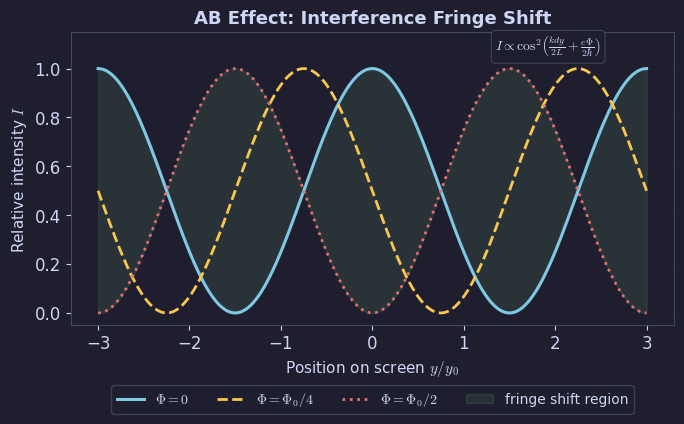

Fig 1.5 saved.


In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))

y = np.linspace(-3, 3, 800)

k = 1.0
d = 2.0 * np.pi
L = 3.0
kdL = k * d / L

def intensity(y, delta_AB):
    return np.cos(kdL * y / 2 + delta_AB / 2)**2

shifts = [0, np.pi/2, np.pi]
labels = [r'$\Phi = 0$', r'$\Phi = \Phi_0/4$', r'$\Phi = \Phi_0/2$']
colors = [BLUE, YELLOW, RED]
styles = ['-', '--', ':']
lws    = [2.2, 2.0, 2.0]

for ds, lbl, col, ls, lw in zip(shifts, labels, colors, styles, lws):
    ax.plot(y, intensity(y, ds), color=col, lw=lw, ls=ls, label=lbl)

ax.fill_between(y,
                intensity(y, 0),
                intensity(y, np.pi),
                alpha=0.10, color=GREEN,
                label='fringe shift region')

ax.set_xlabel(r'Position on screen $y / y_0$', fontsize=11)
ax.set_ylabel(r'Relative intensity $I$', fontsize=11)
ax.set_title('AB Effect: Interference Fringe Shift', color='#cdd6f4')
ax.grid(True, alpha=0.2)
ax.set_ylim(-0.05, 1.15)

# Move legend outside the plot (below)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18),
          ncol=4, facecolor='#1e1e2e', edgecolor='#45475a',
          labelcolor='#cdd6f4', fontsize=10)

ax.text(2.5, 1.07,
        r'$I \propto \cos^2\!\left(\frac{kdy}{2L}+\frac{e\Phi}{2\hbar}\right)$',
        color='#cdd6f4', fontsize=10, ha='right',
        bbox=dict(boxstyle='round,pad=0.3', fc='#1e1e2e', ec='#45475a', lw=0.7))

plt.tight_layout()
SAVE('fig05_AB_interference.png')
plt.show()
print('Fig 1.5 saved.')

## Figure 1.6 — Dirac Monopole Two-Patch Diagram

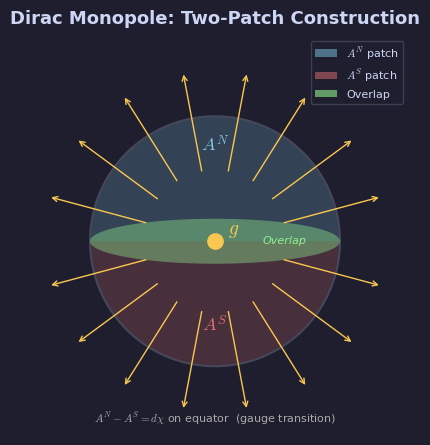

Fig 1.6 saved.


In [7]:
from matplotlib.patches import Polygon
import matplotlib.patches as mpatch

fig, ax = plt.subplots(figsize=(5, 5.5))
ax.set_xlim(-1.55, 1.55)
ax.set_ylim(-1.55, 1.65)
ax.set_aspect('equal')
ax.axis('off')

# Sphere outline
theta = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color='#45475a', lw=1.5)

# Northern patch
phi = np.linspace(0, np.pi, 300)
poly_N = Polygon(np.vstack([np.column_stack([np.cos(phi), np.sin(phi)]),
                             [[-1,0],[1,0]]]),
                 closed=True, fc=BLUE, alpha=0.22, ec='none', zorder=1)
ax.add_patch(poly_N)

# Southern patch
poly_S = Polygon(np.vstack([np.column_stack([np.cos(phi), -np.sin(phi)]),
                             [[1,0],[-1,0]]]),
                 closed=True, fc=RED, alpha=0.22, ec='none', zorder=1)
ax.add_patch(poly_S)

# Equatorial overlap band
band_outer = np.column_stack([np.cos(phi),  np.sin(phi) * 0.18])
band_inner = np.column_stack([np.cos(phi[::-1]), -np.sin(phi[::-1]) * 0.18])
poly_band  = Polygon(np.vstack([band_outer, band_inner]),
                     closed=True, fc=GREEN, alpha=0.40, ec='none', zorder=2)
ax.add_patch(poly_band)

# 'Overlap' label — shifted right to avoid overlap with monopole dot
ax.text(0.38, 0.0, 'Overlap', color=GREEN, ha='left', va='center',
        fontsize=8, style='italic', zorder=3)

# Radial field arrows
for angle_deg in np.linspace(15, 165, 8):
    rad = np.deg2rad(angle_deg)
    ax.annotate('', xy=(1.38*np.cos(rad), 1.38*np.sin(rad)),
                xytext=(0.55*np.cos(rad), 0.55*np.sin(rad)),
                arrowprops=dict(arrowstyle='->', color=YELLOW,
                                lw=1.0, mutation_scale=9), zorder=4)
for angle_deg in np.linspace(195, 345, 8):
    rad = np.deg2rad(angle_deg)
    ax.annotate('', xy=(1.38*np.cos(rad), 1.38*np.sin(rad)),
                xytext=(0.55*np.cos(rad), 0.55*np.sin(rad)),
                arrowprops=dict(arrowstyle='->', color=YELLOW,
                                lw=1.0, mutation_scale=9), zorder=4)

# Monopole g label placed upper-right of dot
ax.plot(0.0, 0.0, 'o', color=YELLOW, ms=11, zorder=10)
ax.text(0.1, 0.06, r'$g$', color=YELLOW, fontsize=14, zorder=11)

# Patch labels
ax.text(0, 0.72, r'$A^N$', color=BLUE, fontsize=13, ha='center', fontweight='bold')
ax.text(0, -0.72, r'$A^S$', color=RED,  fontsize=13, ha='center', fontweight='bold')

ax.text(0, -1.45,
        r'$A^N - A^S = d\chi$ on equator  (gauge transition)',
        color='#aaa', fontsize=8, ha='center')

handles = [mpatch.Patch(fc=BLUE, alpha=0.5, label=r'$A^N$ patch'),
           mpatch.Patch(fc=RED,  alpha=0.5, label=r'$A^S$ patch'),
           mpatch.Patch(fc=GREEN,alpha=0.6, label='Overlap')]
ax.legend(handles=handles, fontsize=8, loc='upper right',
          facecolor='#1e1e2e', edgecolor='#45475a', labelcolor='#cdd6f4')
ax.set_title('Dirac Monopole: Two-Patch Construction', color='#cdd6f4', pad=8)

SAVE('fig06_dirac_monopole.png')
plt.show()
print('Fig 1.6 saved.')

## Figure 1.7 — Zeeman-Split Landau Levels

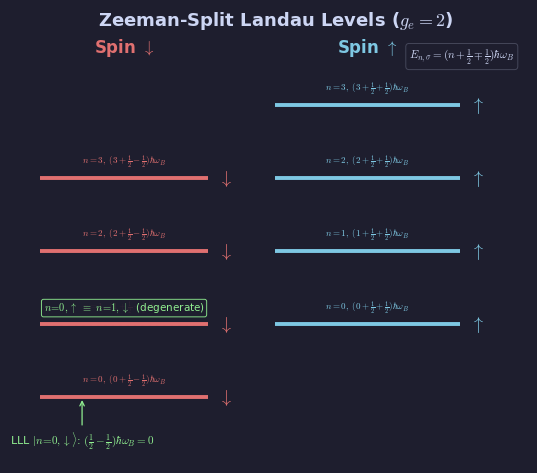

Fig 1.7 saved.


In [8]:
# FIG 1.7 — Zeeman-Split Landau Levels (g_e = 2)
# Correct formula: E_{n,σ} = (n+½)ℏω_B ∓ ½ℏω_B  (g_e=2, − for ↓, + for ↑)
# → E_{n,↓} = n·ℏω_B      (ZPE ½ℏω_B and Zeeman −½ℏω_B cancel exactly)
# → E_{n,↑} = (n+1)·ℏω_B
# LLL (n=0,↓): E = 0  ← ZPE and Zeeman shift cancel exactly

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.set_xlim(0, 6)
ax.set_ylim(-0.9, 4.9)
ax.axis('off')

x_dn_l, x_dn_r = 0.2, 2.2
x_up_l, x_up_r = 3.0, 5.2

for n in range(4):
    E_dn = float(n)      # (n + 1/2 - 1/2) hbar omega_B
    E_up = float(n + 1)  # (n + 1/2 + 1/2) hbar omega_B

    # Spin-down level
    ax.hlines(E_dn, x_dn_l, x_dn_r, colors=RED, linewidths=2.8)
    ax.text(x_dn_r + 0.12, E_dn, r'$\downarrow$',
            color=RED, va='center', fontsize=13)
    # Label: show ZPE cancellation explicitly in parentheses
    dn_lbl = ('$n=' + str(n) + r',\ (' + str(n) +
              r'+\frac{1}{2}-\frac{1}{2})\hbar\omega_B$')
    ax.text((x_dn_l + x_dn_r)/2, E_dn + 0.12,
            dn_lbl, va='bottom', ha='center', color=RED, fontsize=6.5)

    # Spin-up level
    ax.hlines(E_up, x_up_l, x_up_r, colors=BLUE, linewidths=2.8)
    ax.text(x_up_r + 0.12, E_up, r'$\uparrow$',
            color=BLUE, va='center', fontsize=13)
    up_lbl = ('$n=' + str(n) + r',\ (' + str(n) +
              r'+\frac{1}{2}+\frac{1}{2})\hbar\omega_B$')
    ax.text((x_up_l + x_up_r)/2, E_up + 0.12,
            up_lbl, va='bottom', ha='center', color=BLUE, fontsize=6.5)

# Formula summary box (top right)
ax.text(5.85, 4.80,
        r'$E_{n,\sigma}=(n+\frac{1}{2}\mp\frac{1}{2})\hbar\omega_B$',
        color='#cdd6f4', fontsize=8, ha='right', va='top',
        bbox=dict(boxstyle='round,pad=0.3', fc='#1e1e2e', ec='#45475a', lw=0.7))

# Coincident level: n=0,↑ ≡ n=1,↓ at E=ℏω_B
ax.hlines(1.0, x_dn_l, x_dn_r,
          colors=GREEN, linewidths=1.0, linestyles='dashed', alpha=0.8, zorder=1)
ax.text((x_dn_l + x_dn_r)/2, 1.13,
        r'$n\!=\!0,\uparrow\ \equiv\ n\!=\!1,\downarrow$  (degenerate)',
        color=GREEN, fontsize=7.5, ha='center', va='bottom',
        bbox=dict(boxstyle='round,pad=0.2', fc='#1e1e2e', ec=GREEN, lw=0.7, alpha=0.9))

# LLL: explicitly show ZPE and Zeeman cancellation
ax.annotate(
    r'LLL $|n\!=\!0,\downarrow\rangle$: $(\frac{1}{2}-\frac{1}{2})\hbar\omega_B=0$',
    xy=(x_dn_l + 0.5, 0.0), xytext=(x_dn_l + 0.5, -0.65),
    ha='center', color=GREEN, fontsize=8,
    arrowprops=dict(arrowstyle='->', color=GREEN, lw=0.9))

ax.text((x_dn_l+x_dn_r)/2, 4.72, r'Spin $\downarrow$',
        color=RED,  ha='center', fontsize=12, fontweight='bold')
ax.text((x_up_l+x_up_r)/2, 4.72, r'Spin $\uparrow$',
        color=BLUE, ha='center', fontsize=12, fontweight='bold')

ax.set_title(r'Zeeman-Split Landau Levels ($g_e = 2$)', color='#cdd6f4', pad=10)

SAVE('fig07_zeeman_landau.png')
plt.show()
print('Fig 1.7 saved.')


## Figure 1.8 — Bloch Sphere: Spin Precession

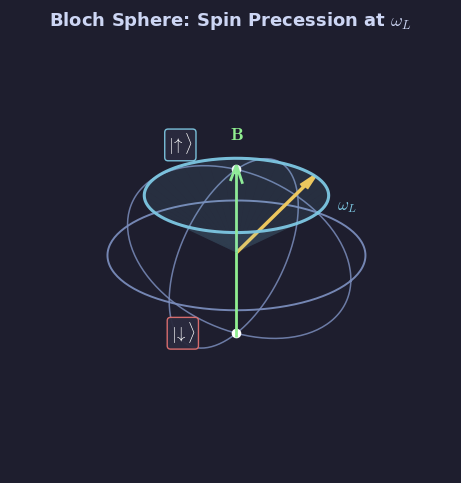

Fig 1.8 saved.


In [9]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(4.8, 4.2))
ax  = fig.add_subplot(111, projection='3d')
ax.set_facecolor('#1e1e2e')
fig.patch.set_facecolor('#1e1e2e')

# Set 3D axes position manually — key to removing whitespace
ax.set_position([0.0, -0.08, 1.0, 1.05])   # [left, bottom, width, height]

# ── Meridians and equator ───────────────────────────────────────
phi_line = np.linspace(0, 2*np.pi, 200)
ax.plot(np.cos(phi_line), np.sin(phi_line), np.zeros_like(phi_line),
        color='#7a8cbb', lw=1.4, alpha=0.95)
for az in [0, np.pi/2]:
    ax.plot(np.sin(phi_line)*np.cos(az),
            np.sin(phi_line)*np.sin(az),
            np.cos(phi_line),
            color='#7a8cbb', lw=1.1, alpha=0.85)

# ── Precession cone trajectory ──────────────────────────────────
theta0 = np.pi / 4
t  = np.linspace(0, 2*np.pi, 300)
cx = np.sin(theta0) * np.cos(t)
cy = np.sin(theta0) * np.sin(t)
cz = np.cos(theta0) * np.ones_like(t)
ax.plot(cx, cy, cz, color=BLUE, lw=2.2, alpha=0.95, zorder=5)

# Cone surface fill (transparent)
n_cone = 40
tc = np.linspace(0, 2*np.pi, n_cone)
cone_verts = [[(0,0,0),
               (np.sin(theta0)*np.cos(tc[i]),   np.sin(theta0)*np.sin(tc[i]),   np.cos(theta0)),
               (np.sin(theta0)*np.cos(tc[i+1]), np.sin(theta0)*np.sin(tc[i+1]), np.cos(theta0))]
              for i in range(n_cone-1)]
ax.add_collection3d(Poly3DCollection(cone_verts, alpha=0.10,
                                      facecolor=BLUE, edgecolor='none'))

# ── Spin vector ─────────────────────────────────────────────────
phi_now = np.pi / 3
sx = np.sin(theta0) * np.cos(phi_now)
sy = np.sin(theta0) * np.sin(phi_now)
sz = np.cos(theta0)
ax.quiver(0, 0, 0, sx, sy, sz,
          color=YELLOW, linewidth=2.5, arrow_length_ratio=0.15, zorder=6)

# ── B-field axis ────────────────────────────────────────────────
ax.quiver(0, 0, -1.05, 0, 0, 2.1,
          color=GREEN, linewidth=2.0, arrow_length_ratio=0.10)
ax.text(-0.17, 0.2, 1.20, r'$\mathbf{B}$', color=GREEN, fontsize=13,
        fontweight='bold')

# ── Poles ───────────────────────────────────────────────────────
ax.scatter([0],[0],[ 1], color='white', s=35, zorder=7)
ax.scatter([0],[0],[-1], color='white', s=35, zorder=7)

# Bracket labels: shifted left to avoid overlap with meridian lines (azim=-60 view)
# North pole — away from lines, bbox + border for clarity
ax.text(-0.55, -0.1, 1.10, r'$|\!\uparrow\rangle$',
        color='white', fontsize=12, fontweight='bold', zorder=10,
        bbox=dict(boxstyle='round,pad=0.2', fc='#2a2a3e', ec=BLUE, lw=1.0, alpha=0.95))
# South pole — same treatment
ax.text(-0.55, -0.1, -1.22, r'$|\!\downarrow\rangle$',
        color='white', fontsize=12, fontweight='bold', zorder=10,
        bbox=dict(boxstyle='round,pad=0.2', fc='#2a2a3e', ec=RED, lw=1.0, alpha=0.95))

# ── ω_L label ───────────────────────────────────────────────────
ax.text(np.sin(theta0)*1.2, 0.05, np.cos(theta0)+0.05,
        r'$\omega_L$', color=BLUE, fontsize=12, fontweight='bold')

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_zlim(-1.1, 1.25)
ax.set_axis_off()
ax.set_title(r'Bloch Sphere: Spin Precession at $\omega_L$',
             color='#cdd6f4', pad=0)
ax.view_init(elev=25, azim=-60)

SAVE('fig08_bloch_precession.png')
plt.show()
print('Fig 1.8 saved.')

---
## ZIP & Download
Run this cell to package all figures and auto-download in Colab.

In [10]:
import shutil, os

zip_path = shutil.make_archive('ch01_figures', 'zip', 'figures/ch01')
print(f'ZIP created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path)/1024:.1f} KB')

# ── Colab auto-download ───────────────────────────────────────
try:
    from google.colab import files
    files.download('ch01_figures.zip')
    print('Download triggered in Colab.')
except ImportError:
    print('Not running in Colab — find ch01_figures.zip in the working directory.')


ZIP created: /content/ch01_figures.zip
Size: 516.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered in Colab.
